# 모델 실험 템플릿

팀 공통 실험 노트북입니다. **이 파일은 고치지 말고 복사해서** 씁니다.
각자 모델 하나(`yolo11m.pt` 또는 `yolo26m.pt`)를 맡아 옵티마이저·lr0 등을 조정합니다.

1. `notebooks/exp_<이름>.ipynb`로 복사합니다.
2. 설정 셀의 **내 실험** 부분만 바꿉니다. **팀 공통** 값은 모두 같아야 서로 점수를 비교할 수 있으므로 바꾸지 않습니다.
3. 순서
   1. 로컬(Mac)에서 `SMOKE = True`로 동작 확인 (epoch 1, 학습 사진 10%, wandb 끔)
   2. Colab GPU에서 `SMOKE = False`, `STAGE = "screen"`: fold 0만 학습해 설정을 고릅니다. 다른 설정과는 fold 0 점수끼리 비교합니다.
   3. 고른 설정은 `STAGE = "confirm"`: 5 fold를 모두 학습합니다. fold 0은 screen 결과를 그대로 씁니다. **모델 비교는 이 5 fold 평균·표준편차로** 합니다.
4. 실험 이름은 설정으로 자동으로 만듭니다 (예: `a_yolo26m_AdamW_lr0.001_cos`). 같은 설정을 다시 돌리면 끝난 fold는 건너뛰고, 끊긴 fold는 `last.pt`에서 이어 학습합니다.
5. 결과는 wandb 팀 프로젝트에 `<실험 이름>/<run>` 이름으로 쌓이고, config에 옵티마이저·lr0 등이 남습니다.
   - Colab: 커널 선택 → **Colab** → GPU 런타임. VS Code 탐색기에서 `.env`를 우클릭 → **Upload to Colab** (`DATA_URL`, `WANDB_API_KEY`, `WANDB_ENTITY`).
   - Colab은 `BRANCH`의 코드를 받아 돌리므로, 로컬에서 고친 `.py`는 push한 뒤 실행합니다.
6. 커밋할 때는 출력을 지웁니다.

## 1. 설정

실험마다 **내 실험**과 **실행** 부분만 바꿉니다. 팀 공통 값을 바꿔야 할 일이 생기면 팀에서 정한 뒤 템플릿을 고칩니다.

In [100]:
# ===== 팀 공통: 바꾸지 않는다 (AGENTS.md 기본값) =====
LABEL = "v1"
SPLITS = ["setup30fix_v1_s42", "combo_v1_s42"]  # 세팅 분할, 조합 분할. 둘 다 학습해 비교한다
EPOCHS = 100
IMGSZ = 640
SEED = 42
AUG = "on"  # models/train.py의 AUG_PRESETS
FRACTION = 1.0

# ===== 내 실험 =====
MEMBER = "kwon"  # 이름이나 이니셜. 실험 이름 맨 앞에 붙는다
MODEL = "yolo11m.pt"  # yolo11m.pt 또는 yolo26m.pt
# SGD, MuSGD, Adam, Adamax, AdamW, NAdam, RAdam, RMSProp. auto는 lr0를 무시하므로 쓰지 않는다
OPTIMIZER = "AdamW"
LR0 = 1e-3  # None이면 SGD 계열 0.01, 그 밖 0.001. 난 이미 0.001로 되어 있음.
COS_LR = False  # True면 학습률을 cosine 곡선으로 줄인다
BATCH = 16  # 팀 기본 16. GPU 메모리가 부족하면 줄인다
# 그 밖 train() 인자. 괄호 안은 ultralytics 기본값
# lrf(0.01), momentum(0.937), weight_decay(0.0005), warmup_epochs(3.0), patience(100)
TRAIN_KWARGS = {}  # 예: {"weight_decay": 0.001, "patience": 30}
TAG = "epoch 100"  # 이름이 같아지는 실험을 구분할 짧은 꼬리표 (선택)

# ===== 실행 =====
SMOKE = False  # True면 동작 확인만. Colab GPU 학습은 False
STAGE = "screen"  # screen: fold 0만, confirm: 5 fold 전부
BRANCH = "exp/yolo11m_adamw"  # Colab에서 받을 브랜치

## 2. 환경

Colab이면 저장소를 받고 패키지를 설치한 뒤 결과 폴더를 Drive에 둡니다. 로컬에서는 프로젝트 루트를 import 경로에 넣기만 합니다.

In [101]:
import os
import sys
from pathlib import Path

IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or Path("/content").is_dir()
RUNS_DIR = None  # None이면 프로젝트의 runs/

if IN_COLAB:
    # colab.ipynb 2–4단계와 같다: 저장소 받기, uv.lock 버전 설치, .env 읽기
    import importlib

    REPO_DIR = Path("/content/pill-bbox")
    if REPO_DIR.exists():
        !git -C {REPO_DIR} fetch -q origin {BRANCH}
        !git -C {REPO_DIR} checkout -q {BRANCH}
        !git -C {REPO_DIR} pull -q
    else:
        !git clone -q -b {BRANCH} https://github.com/def-uk/pill-bbox.git {REPO_DIR}
    os.chdir(REPO_DIR)
    if not Path("~/.local/bin/uv").expanduser().exists():
        !curl -LsSf https://astral.sh/uv/install.sh | sh
    os.environ["PATH"] = f"{Path('~/.local/bin').expanduser()}:{os.environ['PATH']}"
    # torch는 lock에 적힌 CUDA 12.6 빌드로 설치한다
    req = "/tmp/requirements.txt"
    torch_index = "--extra-index-url https://download.pytorch.org/whl/cu126"
    strategy = "--index-strategy unsafe-best-match"
    !uv export -q --frozen --no-dev --no-hashes --no-emit-project -o {req}
    !uv pip install -q --python {sys.executable} -r {req} {torch_index} {strategy}
    sys.path.insert(0, str(REPO_DIR / "notebooks"))
    importlib.invalidate_caches()

    from dotenv import load_dotenv

    load_dotenv("/content/.env")  # 이미 설정된 환경 변수가 우선한다
    for name in ["DATA_URL", "WANDB_API_KEY", "WANDB_ENTITY"]:
        if not os.getenv(name):
            try:
                from google.colab import userdata

                os.environ[name] = userdata.get(name)
            except Exception:
                pass
    if not os.getenv("WANDB_API_KEY"):
        os.environ["WANDB_MODE"] = "disabled"
        print("WANDB_API_KEY가 없어 wandb를 끄고 진행합니다.")

    # 결과를 Drive에 두어야 런타임이 끊겨도 남는다
    try:
        from google.colab import drive

        drive.mount("/content/drive")
        RUNS_DIR = Path("/content/drive/MyDrive/pill-bbox/runs")
    except Exception as e:
        print(f"Drive 연결 실패({e}). 결과가 런타임에만 남으니 끊기기 전에 내려받으세요.")
    !git branch --show-current && git log --oneline -1

# 프로젝트 루트를 import 경로에 넣는다
import nb_data  # noqa: E402, F401

downloading uv 0.13.6 x86_64-unknown-linux-gnu
installing to /usr/local/bin
  uv
  uvx
everything's installed!


Drive 연결 실패(request to https://colab.pa.googleapis.com/v1/credential-propagation:enable failed, reason: ). 결과가 런타임에만 남으니 끊기기 전에 내려받으세요.
exp/yolo11m_adamw
29cae88 (HEAD -> exp/yolo11m_adamw, origin/exp/yolo11m_adamw) exp: 25에폭. 완드비를 위한 수정


## 3. 실험 준비

설정을 검사하고 실험 이름을 만듭니다. 같은 학습을 터미널에서 다시 돌리는 `model_main` 명령을 출력하고, 설정은 `<RUNS_DIR>/<exp>/notebook_config.json`에 남깁니다.

In [102]:
import json
from datetime import datetime

from data_process.split import N_FOLDS
from models.train import default_lr0
from src.config import PROJECT_ROOT, get_device
from src.config import RUNS_DIR as DEFAULT_RUNS_DIR

# 가중치 이름(yolo11m.pt)은 현재 폴더에 받아지므로 루트로 옮겨 팀 공통 위치에 둔다
os.chdir(PROJECT_ROOT)
RUNS_DIR = RUNS_DIR or DEFAULT_RUNS_DIR
DEVICE = get_device()

if not MEMBER:
    raise ValueError("MEMBER에 이름이나 이니셜을 적으세요.")
if MODEL not in ["yolo11m.pt", "yolo26m.pt"]:
    raise ValueError(f"후보 모델은 yolo11m.pt, yolo26m.pt입니다: {MODEL}")
if OPTIMIZER == "auto":
    raise ValueError("auto는 lr0를 무시합니다. 옵티마이저를 직접 고르세요 (예: AdamW).")
if STAGE not in ["screen", "confirm"]:
    raise ValueError(f"STAGE는 screen 또는 confirm입니다: {STAGE}")
lr0 = default_lr0(OPTIMIZER) if LR0 is None else LR0

# 결과 폴더 이름에는 lr0 등이 없으므로, 내 실험 설정을 모두 실험 이름에 넣어 구분한다
parts = [MEMBER, Path(MODEL).stem, OPTIMIZER, f"lr{lr0:g}"]
parts += ["cos"] if COS_LR else []
parts += [] if BATCH == 16 else [f"b{BATCH}"]
parts += [
    f"{key}{value:g}" if isinstance(value, float) else f"{key}{value}"
    for key, value in sorted(TRAIN_KWARGS.items())
]
parts += [TAG] if TAG else []
exp_name = "_".join(parts)

# 동작 확인이면 짧은 값을 쓰고, 실험 이름에 시각을 붙여 이전 확인과 겹치지 않게 한다
if SMOKE:
    exp, epochs, fraction, folds = f"smoke_{exp_name}_{datetime.now():%m%d_%H%M}", 1, 0.1, [0]
    os.environ["WANDB_MODE"] = "disabled"
else:
    if DEVICE != "cuda":
        raise RuntimeError(f"본 학습은 GPU에서 합니다(지금 {DEVICE}). 동작 확인은 SMOKE = True.")
    exp, epochs, fraction = exp_name, EPOCHS, FRACTION
    folds = [0] if STAGE == "screen" else list(range(N_FOLDS))

# 같은 학습을 터미널에서 다시 돌릴 수 있게 model_main 명령으로 남긴다 (분할마다 한 줄)
commands = []
for split in SPLITS:
    cmd = ["uv run python -m models.model_main", "--model", MODEL, "--label", LABEL]
    cmd += ["--split", split, "--folds", *map(str, folds), "--epochs", str(epochs), "--exp", exp]
    cmd += ["--imgsz", str(IMGSZ), "--batch", str(BATCH), "--seed", str(SEED)]
    cmd += ["--fraction", str(fraction), "--aug", AUG, "--optimizer", OPTIMIZER]
    cmd += ["--lr0", f"{lr0:g}"]
    cmd += ["--cos-lr"] if COS_LR else []
    cmd += [] if RUNS_DIR == DEFAULT_RUNS_DIR else ["--runs-dir", str(RUNS_DIR)]
    cmd += ["--resume"]
    commands.append(" ".join(cmd))

config = {
    "exp": exp,
    "member": MEMBER,
    "stage": STAGE,
    "smoke": SMOKE,
    "device": DEVICE,
    "model": MODEL,
    "label": LABEL,
    "splits": SPLITS,
    "folds": folds,
    "epochs": epochs,
    "imgsz": IMGSZ,
    "batch": BATCH,
    "seed": SEED,
    "fraction": fraction,
    "aug": AUG,
    "optimizer": OPTIMIZER,
    "lr0": lr0,
    "cos_lr": COS_LR,
    "train_kwargs": TRAIN_KWARGS,
    "commands": commands,
    "created_at": datetime.now().isoformat(timespec="seconds"),
}
exp_dir = RUNS_DIR / exp
exp_dir.mkdir(parents=True, exist_ok=True)
(exp_dir / "notebook_config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(f"실험 {exp} ({STAGE}, fold {folds}), 장치 {DEVICE}")
print(f"결과 {exp_dir}")
print(*commands, sep="\n")
if TRAIN_KWARGS:
    print(f"추가 train() 인자 (CLI에 없음): {TRAIN_KWARGS}")

실험 kwon_yolo11m_AdamW_lr0.001_epoch 100 (screen, fold [0]), 장치 cuda
결과 /content/pill-bbox/runs/kwon_yolo11m_AdamW_lr0.001_epoch 100
uv run python -m models.model_main --model yolo11m.pt --label v1 --split setup30fix_v1_s42 --folds 0 --epochs 100 --exp kwon_yolo11m_AdamW_lr0.001_epoch 100 --imgsz 640 --batch 16 --seed 42 --fraction 1.0 --aug on --optimizer AdamW --lr0 0.001 --resume
uv run python -m models.model_main --model yolo11m.pt --label v1 --split combo_v1_s42 --folds 0 --epochs 100 --exp kwon_yolo11m_AdamW_lr0.001_epoch 100 --imgsz 640 --batch 16 --seed 42 --fraction 1.0 --aug on --optimizer AdamW --lr0 0.001 --resume


## 4. 데이터

데이터는 `data_process.data_main`으로만 만듭니다. 분할(세팅·조합)마다 fold별 train/val 사진 수를 나란히 보여 줍니다.

In [103]:
import pandas as pd
from nb_data import ensure_pipeline, load_folds

# 라벨·fold·data.yaml이 없으면 data_main을 실행해 만든다 (처음 약 25초, 원본이 없으면 받기부터)
# 분할마다 fold별 train/val 사진 수를 옆으로 나란히 보여 준다
ensure_pipeline(LABEL, SPLITS)
pd.concat(
    {split: load_folds(split).groupby(["fold", "split"]).size().unstack() for split in SPLITS},
    axis=1,
)

setup30fix_v1_s42     combo_v1_s42    
split             train val        train val
fold                                        
0                   189  43          186  46
1                   196  36          184  48
2                   206  26          186  46
3                   202  30          184  48
4                   204  28          188  44

## 5. 학습과 평가

`SPLITS`의 분할마다 fold를 학습하고 평가합니다(분할이 2개면 학습도 2배). `best.pt`는 검증 mAP75-95가 가장 높은 epoch입니다. 런타임이 끊기면 위에서부터 다시 실행하면 이어서 학습합니다.

In [104]:
import time

from models.evaluate import MAIN_METRIC, evaluate_fold, summarize_exp
from models.train import train


def wait_for_file(path: Path, timeout: float = 120.0) -> Path:
    """Drive에 막 다시 쓴 파일은 잠깐 안 보일 수 있어, 나타날 때까지 기다렸다가 경로를 돌려준다."""
    deadline = time.time() + timeout
    while not path.is_file():
        if time.time() > deadline:
            raise FileNotFoundError(f"{timeout:.0f}초를 기다려도 {path}가 없습니다.")
        time.sleep(2)
    return path


# 실험 이름이 설정에서 나오므로 같은 이름 = 같은 설정이다. 그래서 항상 resume으로 돌린다:
# 끝난 fold(screen의 fold 0 등)는 건너뛰고, 끊긴 fold는 last.pt에서 이어 간다.
# 분할마다 결과 폴더가 따로 생긴다(폴더 이름에 분할 이름이 들어간다).
for split in SPLITS:
    for fold in folds:
        save_dir = train(
            MODEL,
            LABEL,
            split,
            fold,
            epochs=epochs,
            exp=exp,
            imgsz=IMGSZ,
            batch=BATCH,
            seed=SEED,
            fraction=fraction,
            aug=AUG,
            optimizer=OPTIMIZER,
            lr0=lr0,
            cos_lr=COS_LR,
            runs_dir=RUNS_DIR,
            resume=True,
            **TRAIN_KWARGS,
        )
        _, summary = evaluate_fold(
            wait_for_file(save_dir / "weights" / "best.pt"),
            LABEL,
            split,
            fold,
            exp=exp,
            imgsz=IMGSZ,
            batch=BATCH,
            runs_dir=RUNS_DIR,
        )
        print(f"{save_dir.name}: {MAIN_METRIC} {summary[MAIN_METRIC]:.4f}")

New https://pypi.org/project/ultralytics/8.4.191 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.14.1+cu126 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pill-bbox/data/processed/yolo/v1/splits/setup30fix_v1_s42/fold_0/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.005, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_d


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      1/100      8.13G      2.006      4.873      1.985         81        640: 100% ━━━━━━━━━━━━ 12/12 1.4it/s 8.8s0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.7s/it 3.4s<10.7s
                   all         43        129      0.175      0.169      0.105     0.0498

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/100      8.17G      1.257      3.674      1.319         82        640: 100% ━━━━━━━━━━━━ 12/12 2.2it/s 5.4s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.3it/s 0.9s2.0s
                   all         43        129     0.0717      0.588      0.087      0.051

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      8.18G      1.104      3.083      1.219        109        640: 100% ━

## 6. 결과 요약

다른 사람·다른 설정과 비교할 때 screen은 fold 0끼리, 모델 비교는 confirm의 5 fold 평균·표준편차로 합니다.

In [105]:
# fold 평균·표준편차. <exp>/results/summary.csv에도 저장된다. screen은 fold 하나라 std가 비어 있다.
summary = summarize_exp(exp, RUNS_DIR)
cols = [("n_folds", "count"), (MAIN_METRIC, "mean"), (MAIN_METRIC, "std")]
cols += [("map50", "mean"), ("map50_95", "mean")]
cols += [(name, "mean") for name in ["precision", "recall", "mean_iou", "recall_≤5"]]
summary[[c for c in cols if c in summary.columns]].round(4)

n_folds map75_95       map50  \
                                           count     mean std    mean   
run                                                                     
yolo11m_combo_v1_s42_augon_optAdamW            1   0.8061 NaN  0.8782   
yolo11m_setup30fix_v1_s42_augon_optAdamW       1   0.6047 NaN  0.8493   

                                         map50_95 precision  recall mean_iou  \
                                             mean      mean    mean     mean   
run                                                                            
yolo11m_combo_v1_s42_augon_optAdamW        0.8422    0.9116  0.8758   0.9608   
yolo11m_setup30fix_v1_s42_augon_optAdamW   0.7270    0.7477  0.6434   0.9091   

                                         recall_≤5  
                                              mean  
run                                                 
yolo11m_combo_v1_s42_augon_optAdamW            0.0  
yolo11m_setup30fix_v1_s42_augon_optAdamW       NaN

### 6-1. 지표 한눈에 보기

두 분할(파랑 = 세팅, 주황 = 조합. 아래 그림 모두 같은 색)의 점수를 막대로 나란히 놓은 그림입니다. 막대 위 숫자는 fold 평균, 검은 선은 fold 간 표준편차입니다(screen은 fold가 하나라 선이 없습니다).

- **main (mAP75-95)**: 박스를 정답과 거의 딱 맞게(IoU 0.75–0.95) 그리면서 약 이름도 맞혔는지 보는 점수입니다. 모델 비교에 쓰는 주 지표입니다.
- **AP (mAP50, mAP50-95)**: 같은 점수를 더 느슨한 기준으로 본 것입니다. mAP50은 "대충 그 자리에 있으면 정답"입니다.
- **aux**: 신뢰도 0.5 이상 예측만 남겼을 때의 값입니다. precision은 "그린 박스 중 맞은 비율", recall은 "실제 알약 중 찾은 비율", mean_iou는 "맞힌 박스가 정답과 얼마나 겹치는지", recall_≤5는 학습 사진이 5개 이하인 희귀 약을 찾은 비율입니다.

**좋은 모습**: 막대가 모두 1에 가깝고, 검은 선(fold마다 다른 정도)이 짧은 것. mAP50은 높은데 mAP75-95만 낮으면 "찾기는 하는데 박스가 조금씩 어긋난다"는 뜻입니다. mean_iou는 0.9를 넘어야 mAP75-95가 잘 오릅니다.

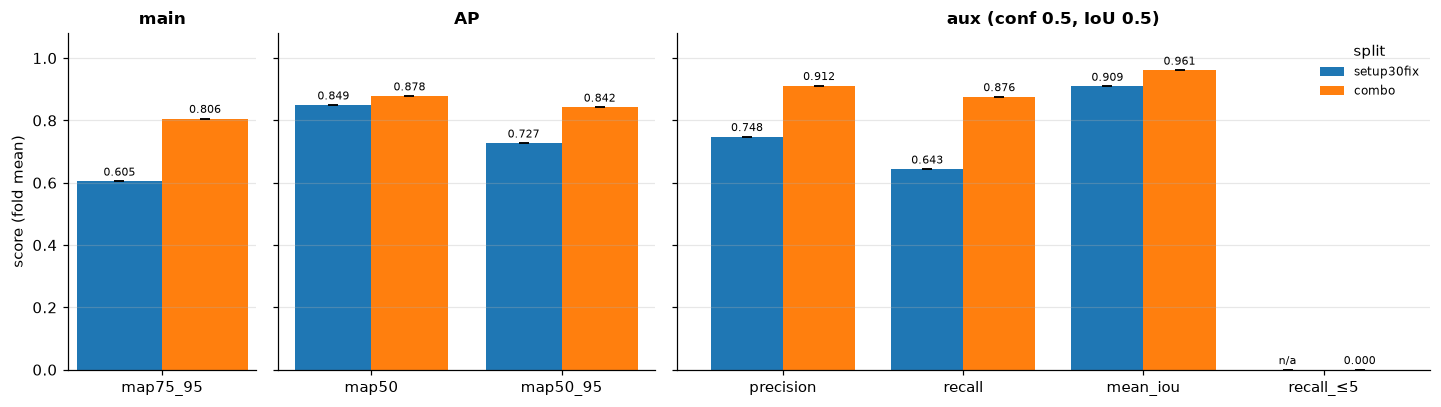

map75_95: combo − setup30fix = +0.2015


,split_name,fold,map75_95,map50,map50_95,precision,recall,mean_iou,recall_≤5
0,combo_v1_s42,0,0.8061,0.8782,0.8422,0.9116,0.8758,0.9608,0.0
1,setup30fix_v1_s42,0,0.6047,0.8493,0.7270,0.7477,0.6434,0.9091,NaN


In [106]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from models.evaluate import FIXED_CONF, MATCH_IOU, results_dir

# 아래 그림 전체에 쓰는 공통 모양: 위·오른쪽 테두리 없음, 옅은 격자, 굵은 제목
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "legend.frameon": False,
    }
)
# 분할마다 모든 그림에서 같은 색을 쓴다 (첫 분할 = 파랑, 둘째 = 주황)
SPLIT_COLORS = {split: f"C{i}" for i, split in enumerate(SPLITS)}


def split_of(run: str) -> str:
    """run 이름(모델_분할_aug<on|off>_opt<옵티마이저>)에서 분할 이름을 찾는다."""
    return next((split for split in SPLITS if f"_{split}_" in f"{run}_"), run)


def split_label(split: str) -> str:
    """그림에 쓸 짧은 분할 이름 (setup30fix, combo)."""
    return split.split("_")[0]


# 주 지표 / AP 계열 / 고정 기준 보조 지표를 칸을 나눠 그린다
METRIC_GROUPS = {
    "main": [MAIN_METRIC],
    "AP": ["map50", "map50_95"],
    f"aux (conf {FIXED_CONF}, IoU {MATCH_IOU})": ["precision", "recall", "mean_iou", "recall_≤5"],
}
fold_summaries = pd.concat(
    [pd.read_csv(p) for p in sorted(results_dir(exp, RUNS_DIR).glob("*_summary.csv"))],
    ignore_index=True,
)
groups = {
    title: [m for m in names if m in fold_summaries.columns]
    for title, names in METRIC_GROUPS.items()
}
groups = {title: names for title, names in groups.items() if names}
if missing := [m for n in METRIC_GROUPS.values() for m in n if m not in fold_summaries.columns]:
    print(f"요약에 없는 지표 {missing}: evaluate.py가 옛 버전이면 BRANCH를 확인하세요.")
metric_names = [m for names in groups.values() for m in names]
done_splits = [split for split in SPLITS if split in set(fold_summaries["split_name"])]
stats = fold_summaries.groupby("split_name")[metric_names].agg(["mean", "std"]).loc[done_splits]

# 막대 = fold 평균, 검은 선 = fold 간 표준편차. 값이 없으면(n/a) 막대 없이 글자만 둔다
fig, axes = plt.subplots(
    1,
    len(groups),
    figsize=(1.6 * len(metric_names) + 2, 3.8),
    sharey=True,
    squeeze=False,
    gridspec_kw={"width_ratios": [len(names) for names in groups.values()]},
)
width = 0.8 / len(stats)
for ax, (title, names) in zip(axes[0], groups.items(), strict=True):
    for i, (split, row) in enumerate(stats.iterrows()):
        x = np.arange(len(names)) + (i - (len(stats) - 1) / 2) * width
        means = row[[(n, "mean") for n in names]].to_numpy(float)
        stds = row[[(n, "std") for n in names]].fillna(0).to_numpy(float)
        bars = ax.bar(
            x,
            np.nan_to_num(means),
            width,
            yerr=stds,
            capsize=3,
            color=SPLIT_COLORS[split],
            label=split_label(split),
        )
        labels = ["n/a" if np.isnan(m) else f"{m:.3f}" for m in means]
        ax.bar_label(bars, labels=labels, fontsize=7, padding=2)
    ax.set_xticks(np.arange(len(names)), names)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0, 0].set_ylim(0, 1.08)
axes[0, 0].set_ylabel("score (fold mean)")
axes[0, -1].legend(title="split", fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()
if len(done_splits) == 2:
    gap = stats[(MAIN_METRIC, "mean")]
    a, b = done_splits
    print(f"{MAIN_METRIC}: {split_label(b)} − {split_label(a)} = {gap[b] - gap[a]:+.4f}")
fold_summaries[["split_name", "fold", *metric_names]].round(4)

### 6-2. 클래스별 AP75-95

약 종류마다 점수를 따로 본 그림입니다. 평균 점수를 깎는 약이 어느 것인지 찾는 데 씁니다.

- **왼쪽**: 한 줄이 약 하나입니다. 두 분할의 점수를 점으로 찍고 회색 선으로 이었습니다. **위쪽일수록 점수가 낮은 약**이고, 점이 없으면 그 분할의 val에 없는 약입니다. 약 번호 글자색은 학습 bbox 수(초록 21개 이상, 주황 6–20개, 빨강 5개 이하)입니다.
- **오른쪽 위**: bbox 수 그룹별 평균 점수입니다.
- **오른쪽 아래**: 가로축은 학습에 쓴 bbox 수, 세로축은 점수입니다. 점 하나가 약 하나입니다.

**좋은 모습**: 왼쪽 점들이 모두 오른쪽(1에 가까운 쪽)에 몰려 있고 회색 선이 짧은 것(분할이 달라도 점수가 비슷함). 오른쪽 위 막대 세 개의 높이가 비슷하면 희귀 약도 흔한 약만큼 잘 맞힌다는 뜻입니다. 오른쪽 아래에서 왼쪽 아래(데이터 적음 + 점수 낮음)에 점이 몰려 있으면 데이터 부족이 원인이고, 데이터가 많은데도 아래에 있는 점은 닮은 약과 헷갈리는 등 약 자체가 어려운 경우입니다.

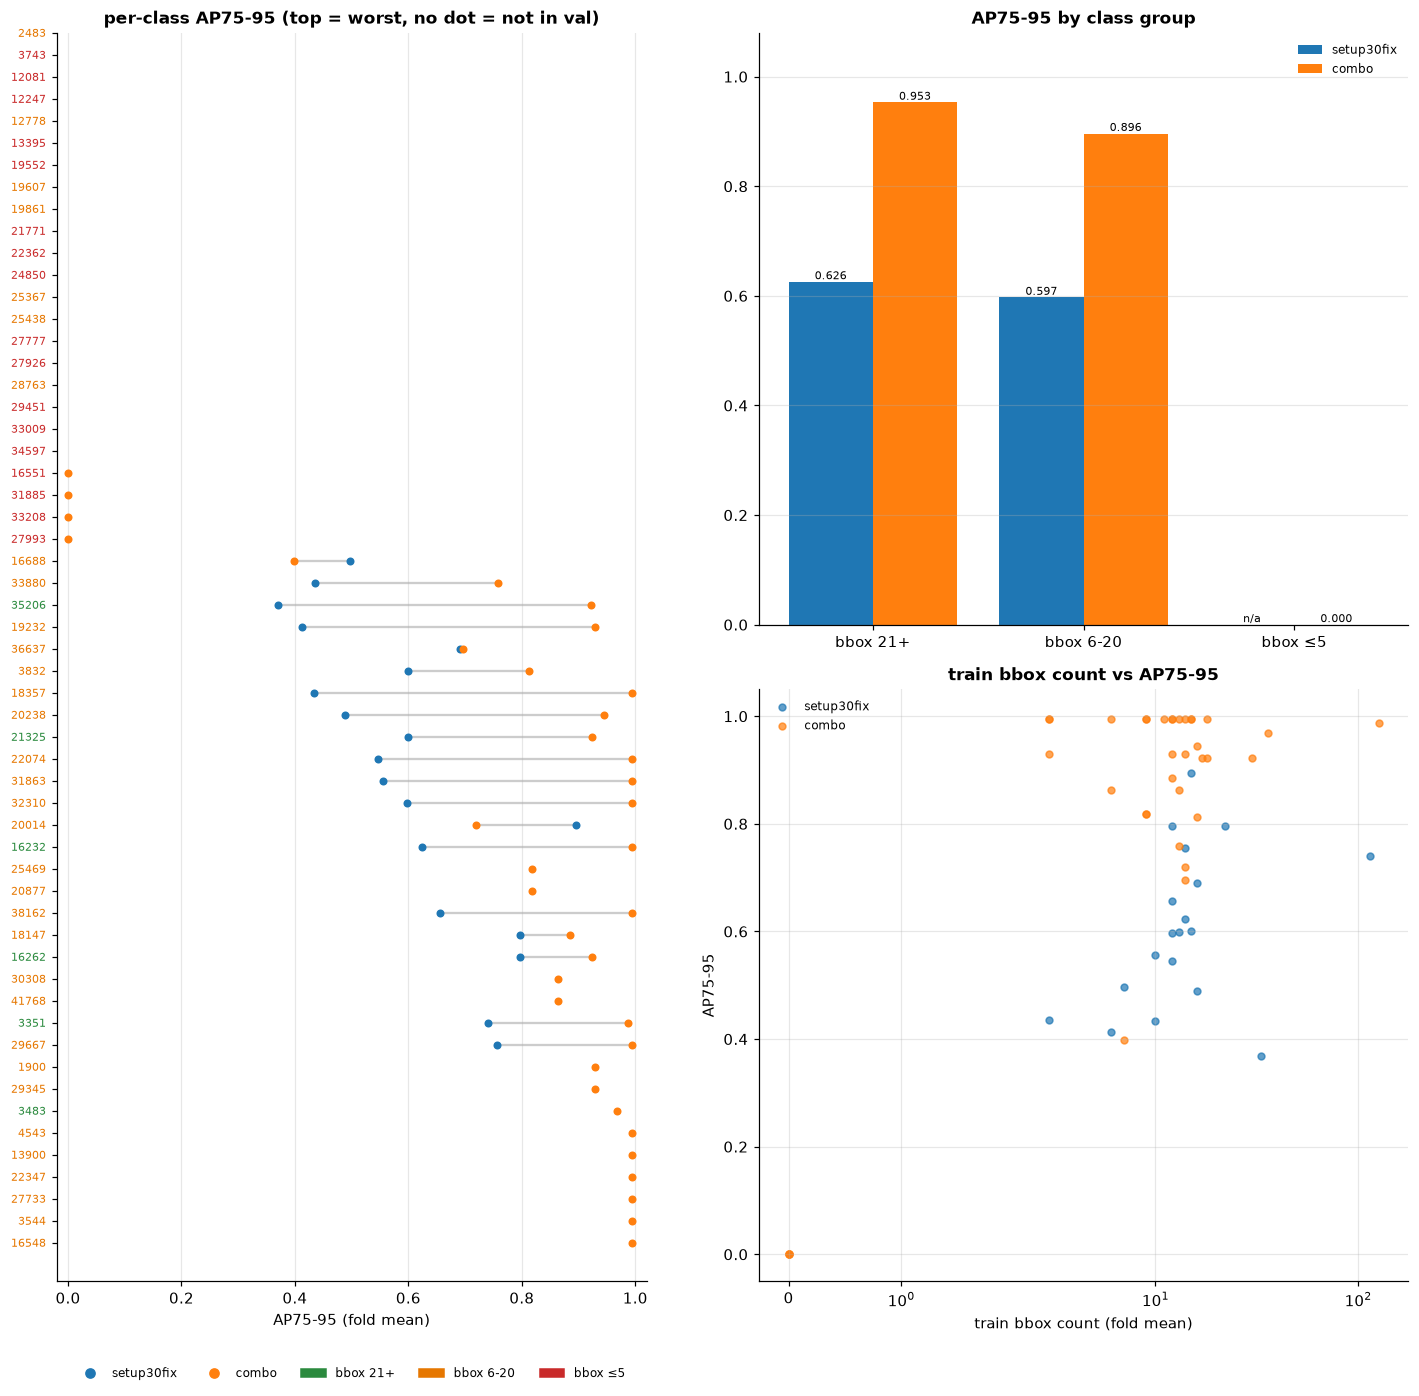

닮은 약 쌍 혼동 수 (fold 합)
            confuse_16262_20238  confuse_16232_21325  confuse_18357_32310
split_name                                                               
combo                         1                    3                    2
setup30fix                    1                    2                    4


,dl_name,group,setup30fix,combo
category_id,,,,
16551,동아가바펜틴정 800mg,≤5,NaN,0.0000
31885,자누메트엑스알서방정 100/1000mg,≤5,NaN,0.0000
33208,에스원엠프정 20mg,≤5,NaN,0.0000
27993,졸로푸트정 100mg,≤5,NaN,0.0000
16688,오마코연질캡슐(오메가-3-산에틸에스테르90),6-20,0.4975,0.3980
33880,글리틴정(콜린알포세레이트),6-20,0.4351,0.7583
35206,아토젯정 10/40mg,21+,0.3694,0.9224
19232,콜리네이트연질캡슐 400mg,6-20,0.4128,0.9290
36637,로수젯정10/5밀리그램,6-20,0.6904,0.6955


In [107]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from models.evaluate import SIZE_GROUPS, results_dir

# 약 번호 글자색 = bbox 수 그룹 (점 색은 분할)
GROUP_COLORS = {"21+": "#2b8a3e", "6-20": "#e67700", "≤5": "#c92a2a"}

# fold별 클래스 표(<run>_fold<k>_per_class.csv)를 분할마다 fold 평균한다
per_class = pd.concat(
    [
        pd.read_csv(p).assign(split=split_of(p.name.rsplit("_fold", 1)[0]))
        for p in sorted(results_dir(exp, RUNS_DIR).glob("*_per_class.csv"))
    ],
    ignore_index=True,
)
class_avg = (
    per_class.groupby(["split", "category_id"])
    .agg(
        dl_name=("dl_name", "first"),
        group=("group", "first"),
        ap75_95=("ap75_95", "mean"),
        n_train=("n_train_bbox", "mean"),
    )
    .reset_index()
)
wide = class_avg.pivot(index="category_id", columns="split", values="ap75_95")[done_splits]
info = class_avg.drop_duplicates("category_id").set_index("category_id")[["dl_name", "group"]]
order = wide.mean(axis=1).sort_values(na_position="first").index  # 위쪽 = 낮은 점수

fig = plt.figure(figsize=(13, 0.2 * len(order) + 1.5))
grid = fig.add_gridspec(2, 2, width_ratios=[1, 1.1])

# 왼쪽: 약마다 분할별 AP75-95를 점으로 찍고 회색 선으로 이어 차이를 본다
ax = fig.add_subplot(grid[:, 0])
y = np.arange(len(order))
ax.hlines(y, wide.loc[order].min(axis=1), wide.loc[order].max(axis=1), color="0.8", zorder=1)
for split in done_splits:
    ax.scatter(wide.loc[order, split], y, color=SPLIT_COLORS[split], s=18, zorder=3)
ax.set_yticks(y, [str(c) for c in order], fontsize=7)
for tick, c in zip(ax.get_yticklabels(), order, strict=True):
    tick.set_color(GROUP_COLORS.get(info.loc[c, "group"], "black"))
ax.invert_yaxis()
ax.set_xlim(-0.02, 1.02)
ax.set_xlabel("AP75-95 (fold mean)")
ax.set_title("per-class AP75-95 (top = worst, no dot = not in val)")
ax.grid(axis="y", visible=False)
split_handles = [
    Line2D([], [], marker="o", ls="", color=SPLIT_COLORS[s], label=split_label(s))
    for s in done_splits
]
group_handles = [Patch(color=GROUP_COLORS[name], label=f"bbox {name}") for _, name in SIZE_GROUPS]
ax.legend(
    handles=split_handles + group_handles,
    fontsize=8,
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.06),
)

# 오른쪽 위: 그룹별 평균을 분할끼리 나란히. 값이 없으면 n/a
ax = fig.add_subplot(grid[0, 1])
group_cols = [f"ap75_95_{name}" for _, name in SIZE_GROUPS]
group_avg = fold_summaries.groupby("split_name")[group_cols].mean()
width = 0.8 / len(done_splits)
for i, split in enumerate(done_splits):
    values = group_avg.loc[split].to_numpy(float)
    x = np.arange(len(group_cols)) + (i - (len(done_splits) - 1) / 2) * width
    bars = ax.bar(
        x, np.nan_to_num(values), width, color=SPLIT_COLORS[split], label=split_label(split)
    )
    ax.bar_label(bars, labels=["n/a" if np.isnan(v) else f"{v:.3f}" for v in values], fontsize=7)
ax.set_xticks(np.arange(len(group_cols)), [f"bbox {name}" for _, name in SIZE_GROUPS])
ax.set_ylim(0, 1.08)
ax.set_title("AP75-95 by class group")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8)

# 오른쪽 아래: 학습 bbox 수가 많을수록 점수가 높은가
ax = fig.add_subplot(grid[1, 1])
for split in done_splits:
    table = class_avg[class_avg["split"] == split]
    ax.scatter(
        table["n_train"],
        table["ap75_95"],
        color=SPLIT_COLORS[split],
        s=20,
        alpha=0.7,
        label=split_label(split),
    )
ax.set_xscale("symlog")
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("train bbox count (fold mean)")
ax.set_ylabel("AP75-95")
ax.set_title("train bbox count vs AP75-95")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# 닮은 약 쌍 혼동 수(fold 합)와 평균 점수가 낮은 약 10개를 분할끼리 나란히
confuse_cols = [c for c in fold_summaries.columns if c.startswith("confuse_")]
print("닮은 약 쌍 혼동 수 (fold 합)")
print(fold_summaries.groupby("split_name")[confuse_cols].sum().rename(index=split_label))
worst = wide.loc[order].dropna(how="all").head(10).rename(columns=split_label)
info.join(worst, how="right").round(4)

### 6-3. 예측 그림

모델이 실제 사진에서 어떻게 답했는지 눈으로 확인하는 그림입니다. 분할마다 첫 fold의 `best.pt`로 val 사진을 예측하고 **한 줄에 한 분할씩** 몇 장을 그립니다(장수는 `N_SHOW`). 6-4~6-6도 이 칸의 예측을 씁니다.

- 초록 실선 = 정답 박스와 약 번호, 빨강 점선 = 모델 예측(신뢰도 0.5 이상)과 약 번호·신뢰도
- 사진 제목의 `GT 3 · pred 2`는 정답 3개 중 예측이 2개 나왔다는 뜻입니다.

**좋은 모습**: 모든 초록 박스 위에 빨강 점선이 거의 겹쳐 있고, 두 박스의 약 번호가 같고, 신뢰도가 0.9 가까이 높은 것. 볼 점은 세 가지입니다. 초록만 있고 빨강이 없으면 **놓친 알약**, 박스는 맞는데 번호가 다르면 **약 이름을 틀린 것**, 빨강이 초록보다 조금 크거나 작으면 **박스가 어긋난 것**(mAP75-95를 깎음)입니다.

setup30fix: val 사진 43장, 정답 129개, 예측(conf ≥ 0.5) 111개
combo: val 사진 46장, 정답 153개, 예측(conf ≥ 0.5) 147개


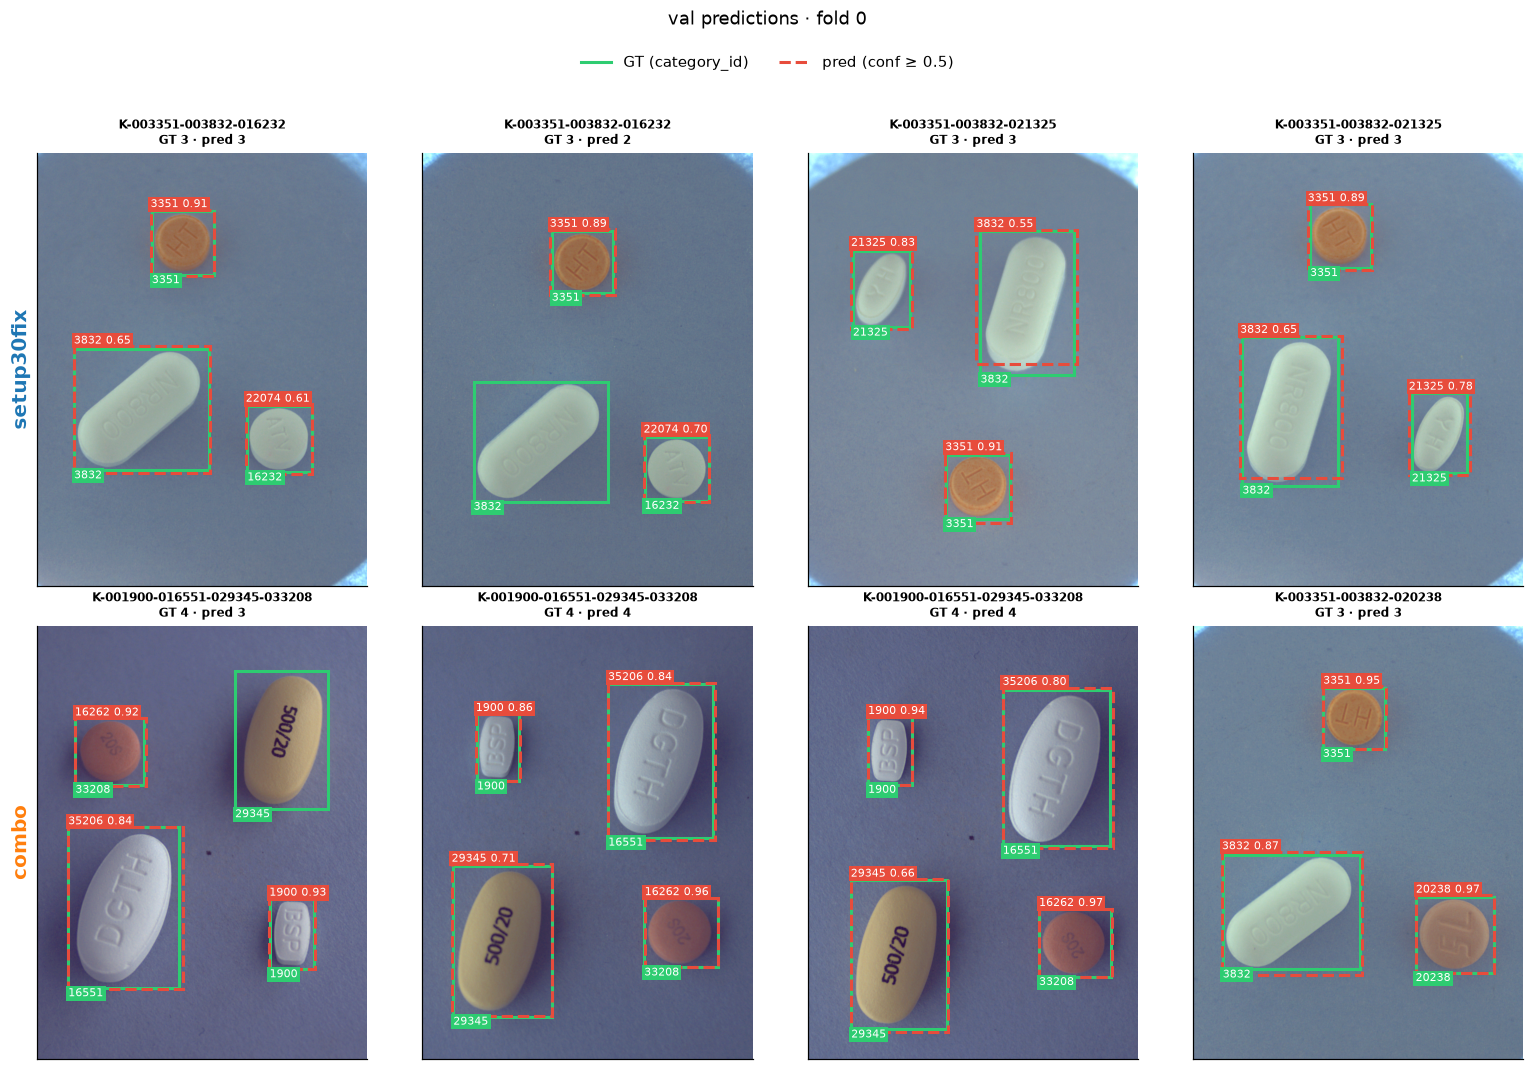

In [108]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from ultralytics import YOLO

from data_process.data_yaml import data_yaml_path, load_class_map
from models.evaluate import FIXED_CONF, PROCESSED_DIR, predict_images

N_SHOW = 4  # 분할마다 그릴 val 사진 수
LOW_CONF = 0.1  # 6-4 신뢰도별 곡선을 그리려고 낮은 기준으로 한 번만 예측하고, 쓸 때 거른다
SHOW_FOLD = folds[0]
GT_COLOR, PRED_COLOR = "#2ecc71", "#e74c3c"

# 분할마다 이 fold의 best.pt로 val 사진 전체를 예측한다. 6-4~6-6도 이 결과를 쓴다
class_map = load_class_map(LABEL)
to_category = dict(zip(class_map["yolo_idx"], class_map["category_id"], strict=True))
labels = pd.read_csv(PROCESSED_DIR / "labels" / f"labels_{LABEL}.csv")
group_of = per_class.drop_duplicates("category_id").set_index("category_id")["group"]
weights_of, val_paths_of, preds, truths = {}, {}, {}, {}
for split in done_splits:
    found = sorted(exp_dir.glob(f"*_{split}_*_fold{SHOW_FOLD}/weights/best.pt"))
    if not found:
        raise FileNotFoundError(
            f"{split} fold {SHOW_FOLD}의 best.pt가 없습니다. 5번 칸을 확인하세요."
        )
    weights_of[split] = found[0]
    val_txt = data_yaml_path(LABEL, split, SHOW_FOLD).parent / "val.txt"
    val_paths_of[split] = val_txt.read_text(encoding="utf-8").split()
    preds[split] = predict_images(YOLO(found[0]), val_paths_of[split], to_category, IMGSZ, LOW_CONF)
    names = {Path(p).name for p in val_paths_of[split]}
    truths[split] = labels[labels["file_name"].isin(names)].assign(
        group=lambda d: d["category_id"].map(group_of)
    )
    n_pred = (preds[split]["conf"] >= FIXED_CONF).sum()
    print(
        f"{split_label(split)}: val 사진 {len(names)}장, 정답 {len(truths[split])}개, "
        f"예측(conf ≥ {FIXED_CONF}) {n_pred}개"
    )


def draw_box(ax: plt.Axes, xywh: tuple, text: str, color: str, dashed: bool) -> None:
    """박스와 색 배경 글자를 그린다. 정답은 박스 아래, 예측은 박스 위에 글자를 둔다."""
    x, y, w, h = xywh
    ax.add_patch(
        Rectangle((x, y), w, h, fill=False, edgecolor=color, lw=2, ls="--" if dashed else "-")
    )
    ax.text(
        x,
        y if dashed else y + h,
        text,
        color="white",
        fontsize=7,
        va="bottom" if dashed else "top",
        bbox={"facecolor": color, "edgecolor": "none", "pad": 1.5},
    )


# 한 줄 = 한 분할. 줄 왼쪽에 분할 이름을 적는다
fig, axes = plt.subplots(
    len(done_splits), N_SHOW, figsize=(3.6 * N_SHOW, 4.7 * len(done_splits)), squeeze=False
)
for row_axes, split in zip(axes, done_splits, strict=True):
    truth = truths[split]
    pred = preds[split][preds[split]["conf"] >= FIXED_CONF]
    show_paths = val_paths_of[split][:N_SHOW]
    for ax, path in zip(row_axes, show_paths, strict=False):
        file_name = Path(path).name
        gt = truth[truth["file_name"] == file_name]
        pr = pred[pred["file_name"] == file_name]
        ax.imshow(plt.imread(path))
        for row in gt.itertuples():
            draw_box(ax, (row.x, row.y, row.w, row.h), str(row.category_id), GT_COLOR, False)
        for row in pr.itertuples():
            text = f"{row.category_id} {row.conf:.2f}"
            draw_box(ax, (row.x, row.y, row.w, row.h), text, PRED_COLOR, True)
        ax.set_title(f"{file_name.split('_')[0]}\nGT {len(gt)} · pred {len(pr)}", fontsize=8)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    for ax in row_axes[len(show_paths) :]:
        ax.set_visible(False)
    row_axes[0].set_ylabel(
        split_label(split), fontsize=13, fontweight="bold", color=SPLIT_COLORS[split]
    )
fig.legend(
    handles=[
        Line2D([], [], color=GT_COLOR, lw=2, label="GT (category_id)"),
        Line2D([], [], color=PRED_COLOR, lw=2, ls="--", label=f"pred (conf ≥ {FIXED_CONF})"),
    ],
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.0),
)
fig.suptitle(f"val predictions · fold {SHOW_FOLD}", y=1.03)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

### 6-4. 신뢰도 기준별 보조 지표

"신뢰도 몇 이상인 예측만 믿을까"를 0.1부터 0.9까지 바꿔 보며 정밀도·재현율 등을 다시 계산한 그림입니다. 분할마다 한 칸이고, 회색 점선이 지금 쓰는 고정 기준 0.5입니다.

- 기준을 **높이면** 확실한 예측만 남아 precision(맞은 비율)은 오르고, recall(찾은 비율)은 떨어집니다. 기준을 낮추면 반대입니다.
- mean_iou는 맞힌 박스가 얼마나 잘 겹치는지, recall_≤5는 희귀 약을 찾은 비율입니다.

**좋은 모습**: precision과 recall이 넓은 구간에서 **둘 다 0.9 위**에 머무는 것. 좋은 모델은 맞는 예측에 신뢰도를 높게 주므로 기준을 올려도 recall이 잘 떨어지지 않습니다. 두 선이 교차하는 지점이 0.5보다 훨씬 왼쪽이면 모델이 아직 자신 없게 답하고 있다는 뜻입니다. recall_≤5가 기준과 관계없이 0이면 문턱값 문제가 아니라 그 약을 아예 못 배운 것입니다.

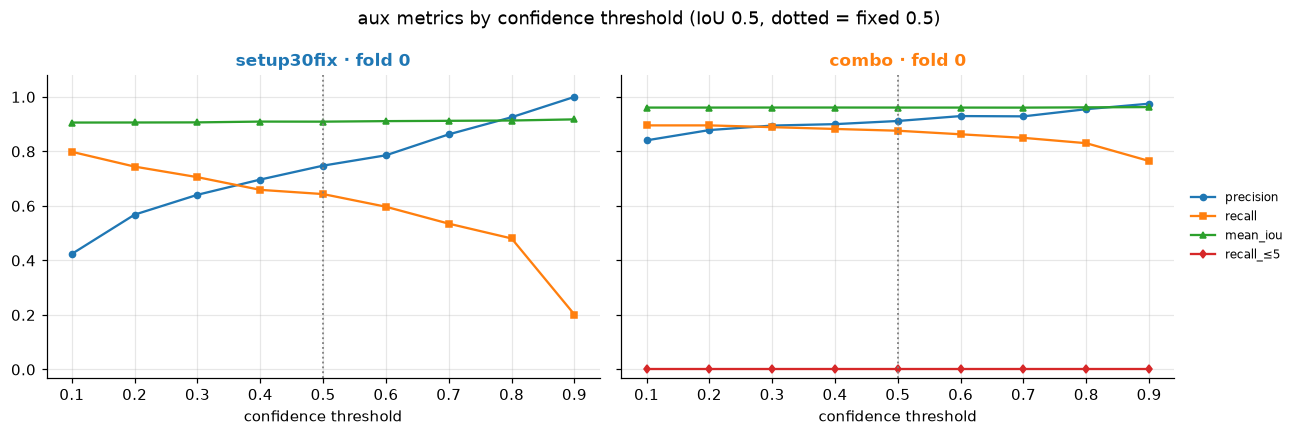

setup30fix                                combo                   \
      precision  recall mean_iou recall_≤5 precision  recall mean_iou   
conf                                                                    
0.1      0.4239  0.7984   0.9058       NaN    0.8405  0.8954   0.9608   
0.2      0.5680  0.7442   0.9060       NaN    0.8782  0.8954   0.9608   
0.3      0.6408  0.7054   0.9064       NaN    0.8947  0.8889   0.9609   
0.4      0.6967  0.6589   0.9093       NaN    0.9000  0.8824   0.9609   
0.5      0.7477  0.6434   0.9091       NaN    0.9116  0.8758   0.9608   
0.6      0.7857  0.5969   0.9110       NaN    0.9296  0.8627   0.9607   
0.7      0.8625  0.5349   0.9122       NaN    0.9286  0.8497   0.9606   
0.8      0.9254  0.4806   0.9133       NaN    0.9549  0.8301   0.9616   
0.9      1.0000  0.2016   0.9175       NaN    0.9750  0.7647   0.9625   

                
     recall_≤5  
conf            
0.1        0.0  
0.2        0.0  
0.3        0.0  
0.4        0.0  
0.5        0.0  
0.6        0.0  
0.7        0.0  
0.8        0.0  
0.9        0.0

In [109]:
import numpy as np

from models.evaluate import fixed_conf_metrics

# 신뢰도 기준을 바꿔 가며 보조 지표를 다시 계산한다. 분할마다 한 칸, 회색 점선이 고정 기준이다
CONF_GRID = np.round(np.arange(LOW_CONF, 0.95, 0.1), 2)
AUX = [("precision", "o"), ("recall", "s"), ("mean_iou", "^"), ("recall_≤5", "d")]
curves = {}
fig, axes = plt.subplots(
    1, len(done_splits), figsize=(5.2 * len(done_splits) + 1.5, 4), sharey=True, squeeze=False
)
for ax, split in zip(axes[0], done_splits, strict=True):
    curve = pd.DataFrame(
        [
            {"conf": conf, **fixed_conf_metrics(preds[split], truths[split], conf=conf)}
            for conf in CONF_GRID
        ]
    )
    curves[split_label(split)] = curve.set_index("conf")
    for name, marker in AUX:
        ax.plot(curve["conf"], curve[name], marker=marker, markersize=4, lw=1.5, label=name)
    ax.axvline(FIXED_CONF, color="gray", linestyle=":", lw=1.2)
    ax.set_xticks(CONF_GRID)
    ax.set_xlabel("confidence threshold")
    ax.set_title(f"{split_label(split)} · fold {SHOW_FOLD}", color=SPLIT_COLORS[split])
axes[0, 0].set_ylim(-0.03, 1.08)
axes[0, -1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.suptitle(f"aux metrics by confidence threshold (IoU {MATCH_IOU}, dotted = fixed {FIXED_CONF})")
fig.tight_layout()
plt.show()
pd.concat(curves, axis=1).round(4)

### 6-5. 박스 맞춤과 놓친 알약

- **왼쪽**: 맞힌 박스 하나하나가 정답과 얼마나 겹치는지(IoU)를 모은 막대 분포입니다. IoU 1이면 완전히 겹친 것이고, 색칠한 0.75 이상 구간이 주 지표가 보는 범위입니다.
- **오른쪽**: 사진마다 (예측 박스 수 − 정답 알약 수)를 센 비율입니다. 0이면 개수가 맞은 것, −1은 알약 1개를 놓친 것, +1은 없는 박스를 하나 더 그린 것입니다. val 사진 수가 분할마다 달라 %로 그립니다. 약 이름은 보지 않고 개수만 셉니다.

**좋은 모습**: 왼쪽 분포가 **0.9–1.0 쪽에 높고 좁게** 솟아 있는 것. 0.85 근처에 몰려 있으면 박스가 꾸준히 조금씩 어긋나서 IoU 0.90·0.95 기준을 통과하지 못하므로 mAP75-95가 낮아집니다. 오른쪽은 **0 막대 하나만 100%에 가깝게** 높은 것이 좋습니다. 음수가 많으면 놓치는 문제, 양수가 많으면 헛박스(중복 박스 등) 문제입니다.

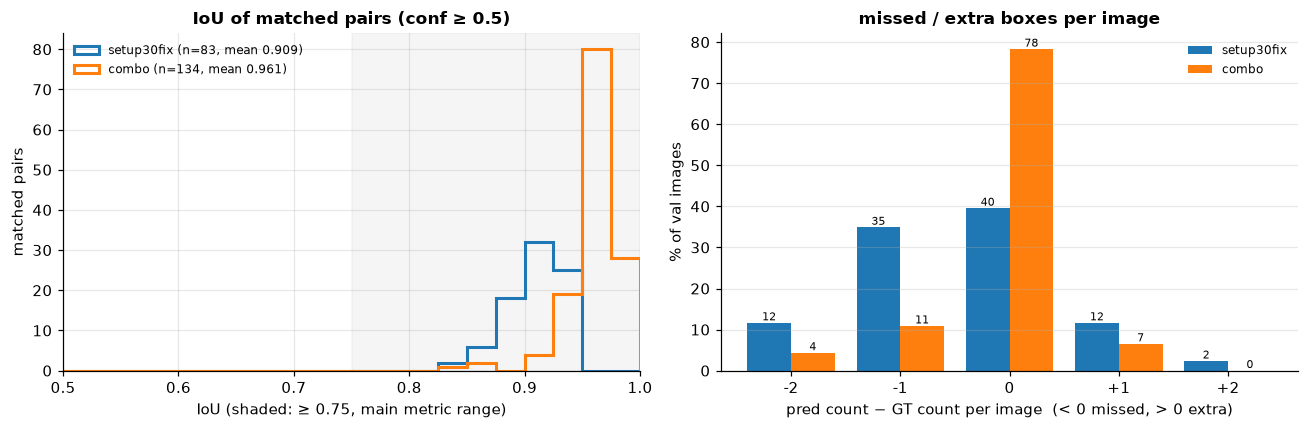

In [110]:
from models.evaluate import match_boxes

# 왼쪽: 짝지어진 (정답, 예측) 쌍의 IoU 분포. 색칠한 0.75 이상 구간이 많을수록 주 지표가 오른다
# 오른쪽: 사진마다 (예측 수 − 정답 수). 음수는 놓친 알약, 양수는 더 찾은 박스
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].axvspan(0.75, 1.0, color="0.5", alpha=0.08)
diffs = {}
for i, split in enumerate(done_splits):
    truth = truths[split]
    pred = preds[split][preds[split]["conf"] >= FIXED_CONF]
    ious = []
    for file_name, gt in truth.groupby("file_name"):
        ious += match_boxes(pred[pred["file_name"] == file_name], gt)[1]
    label = split_label(split)
    if ious:
        axes[0].hist(
            ious,
            bins=np.arange(MATCH_IOU, 1.0001, 0.025),
            histtype="step",
            lw=2,
            color=SPLIT_COLORS[split],
            label=f"{label} (n={len(ious)}, mean {np.mean(ious):.3f})",
        )
    else:
        axes[0].text(
            0.03,
            0.9 - 0.08 * i,
            f"{label}: no matched pairs",
            fontsize=8,
            color=SPLIT_COLORS[split],
            transform=axes[0].transAxes,
        )
    diffs[split] = (
        pred.groupby("file_name").size().reindex(truth["file_name"].unique(), fill_value=0)
        - truth.groupby("file_name").size()
    ).value_counts(normalize=True)
axes[0].set_xlim(MATCH_IOU, 1.0)
axes[0].set_xlabel("IoU (shaded: ≥ 0.75, main metric range)")
axes[0].set_ylabel("matched pairs")
axes[0].set_title(f"IoU of matched pairs (conf ≥ {FIXED_CONF})")
if axes[0].get_legend_handles_labels()[0]:
    axes[0].legend(fontsize=8, loc="upper left")

# 분할마다 val 사진 수가 달라 비율(%)로 나란히 비교한다
ax = axes[1]
values = sorted(set().union(*[d.index for d in diffs.values()]))
width = 0.8 / len(diffs)
for i, (split, share) in enumerate(diffs.items()):
    x = np.arange(len(values)) + (i - (len(diffs) - 1) / 2) * width
    heights = share.reindex(values, fill_value=0).to_numpy() * 100
    bars = ax.bar(x, heights, width, color=SPLIT_COLORS[split], label=split_label(split))
    ax.bar_label(bars, fmt="%.0f", fontsize=7)
ax.set_xticks(np.arange(len(values)), [f"{v:+d}" if v else "0" for v in values])
ax.set_xlabel("pred count − GT count per image  (< 0 missed, > 0 extra)")
ax.set_ylabel("% of val images")
ax.set_title("missed / extra boxes per image")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 6-6. ultralytics 평가 그림

평가 때 ultralytics가 저장한 그림 세 종류를 분할끼리 나란히 봅니다.

- **혼동 행렬(정규화)**: 가로가 실제 약, 세로가 모델이 답한 약입니다. 칸이 진할수록 그 조합이 많습니다. 맨 끝 background는 "알약을 못 찾음" 또는 "알약이 없는 곳에 박스를 그림"입니다.
  - **좋은 모습**: 왼쪽 위에서 오른쪽 아래로 가는 **대각선만 진하고** 나머지는 하얀 것. 대각선 밖의 진한 칸은 그 두 약을 헷갈린다는 뜻입니다.
- **PR 곡선**: 가로가 재현율(찾은 비율), 세로가 정밀도(맞은 비율)입니다. 곡선 아래 넓이가 AP이고, 범례의 숫자가 약별 AP50, 굵은 파란 선이 전체 평균입니다.
  - **좋은 모습**: 곡선이 **오른쪽 위 모서리(1, 1)에 붙어** 네모에 가까운 것. 일찍 아래로 꺾이거나 낮은 높이에서 평평한 선은 오답이 많은 약입니다.
- **F1 곡선**: 가로가 신뢰도 기준, 세로가 F1(정밀도와 재현율을 함께 본 점수)입니다. 범례에 최고 F1과 그때의 신뢰도가 적혀 있습니다.
  - **좋은 모습**: 굵은 파란 선이 **넓은 구간에서 높고 평평하며**, 최고점이 0.5 근처 이상에 있는 것. 최고점이 0.1 근처로 왼쪽에 있으면 모델이 맞는 답에도 신뢰도를 낮게 준다는 뜻입니다.

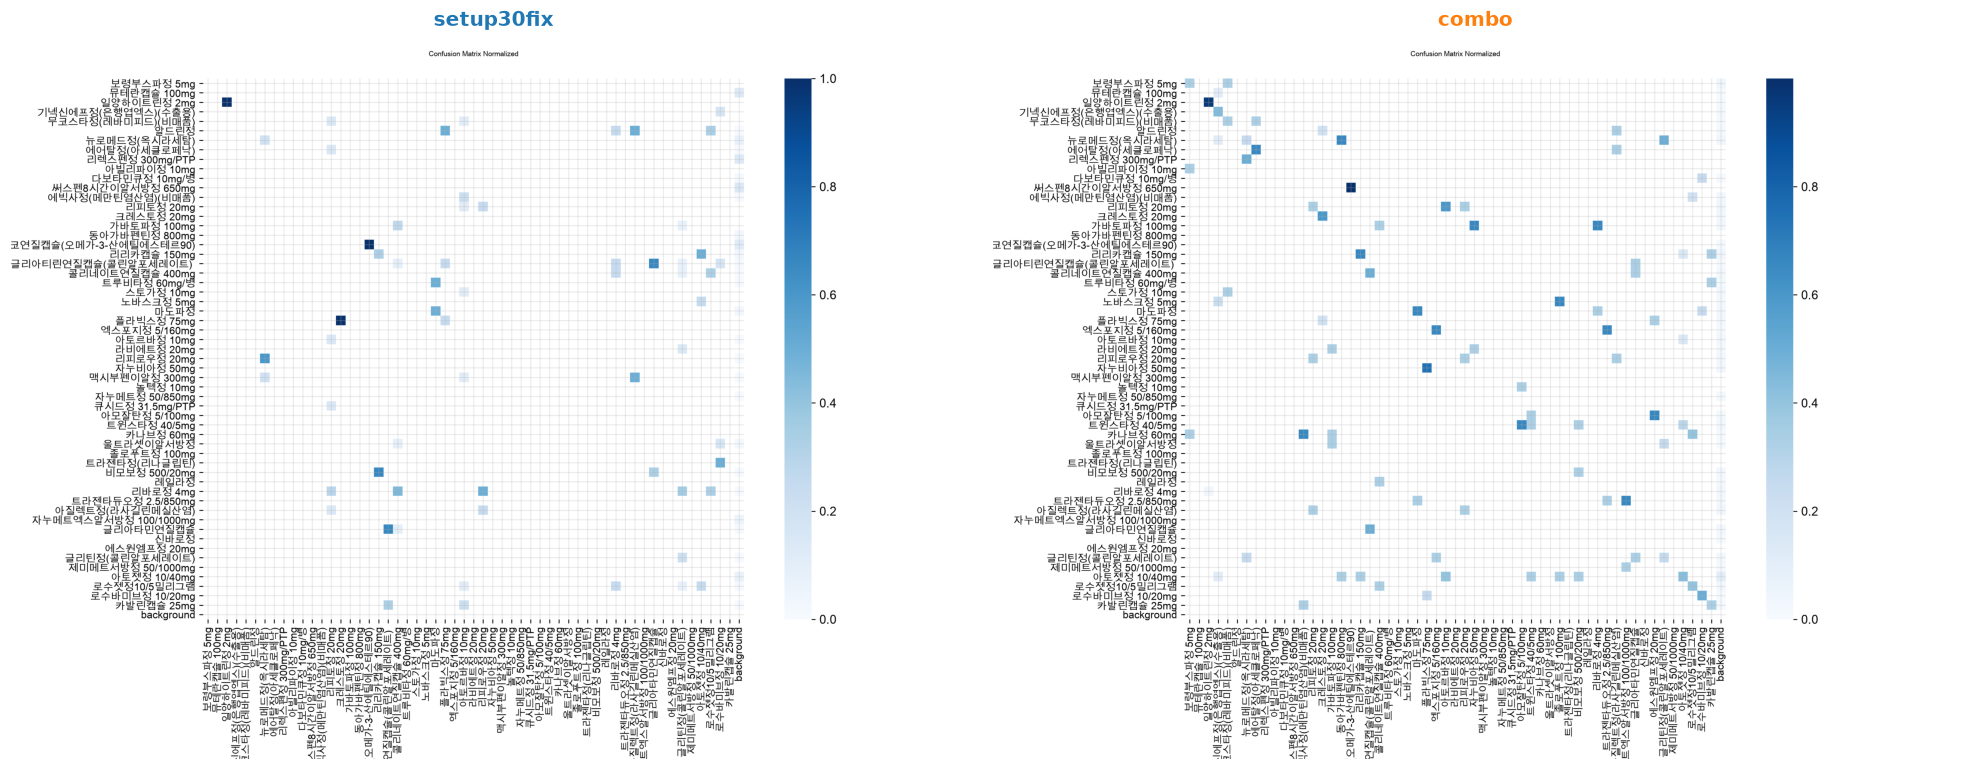

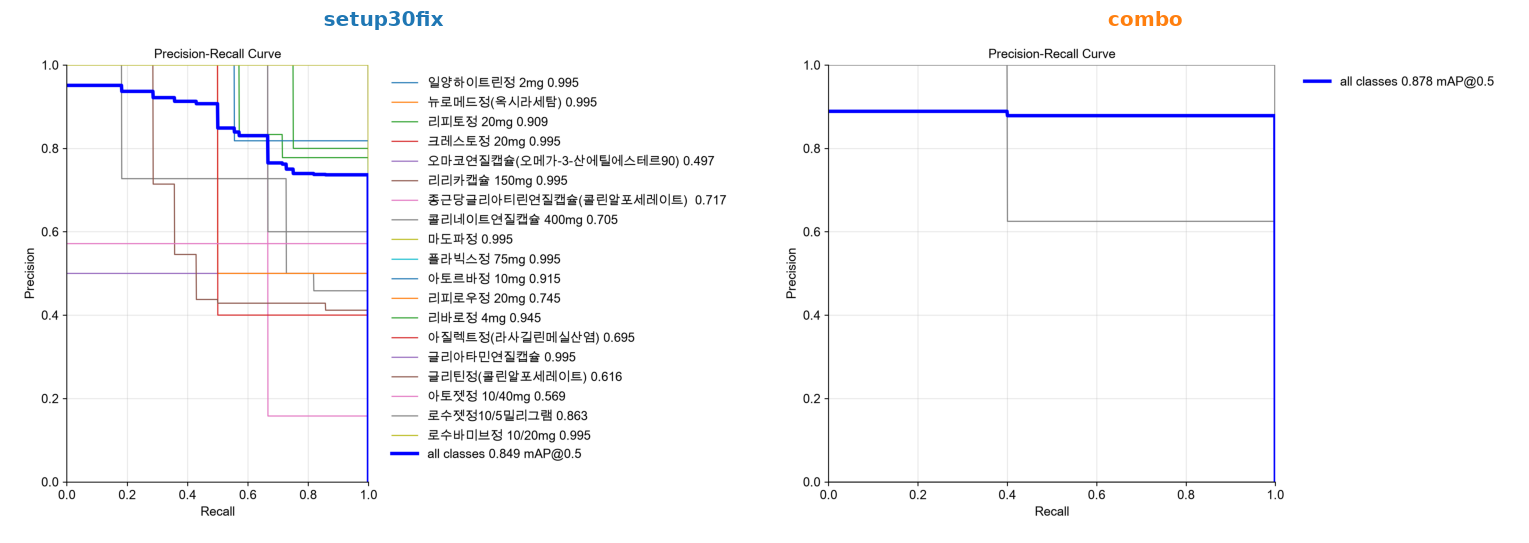

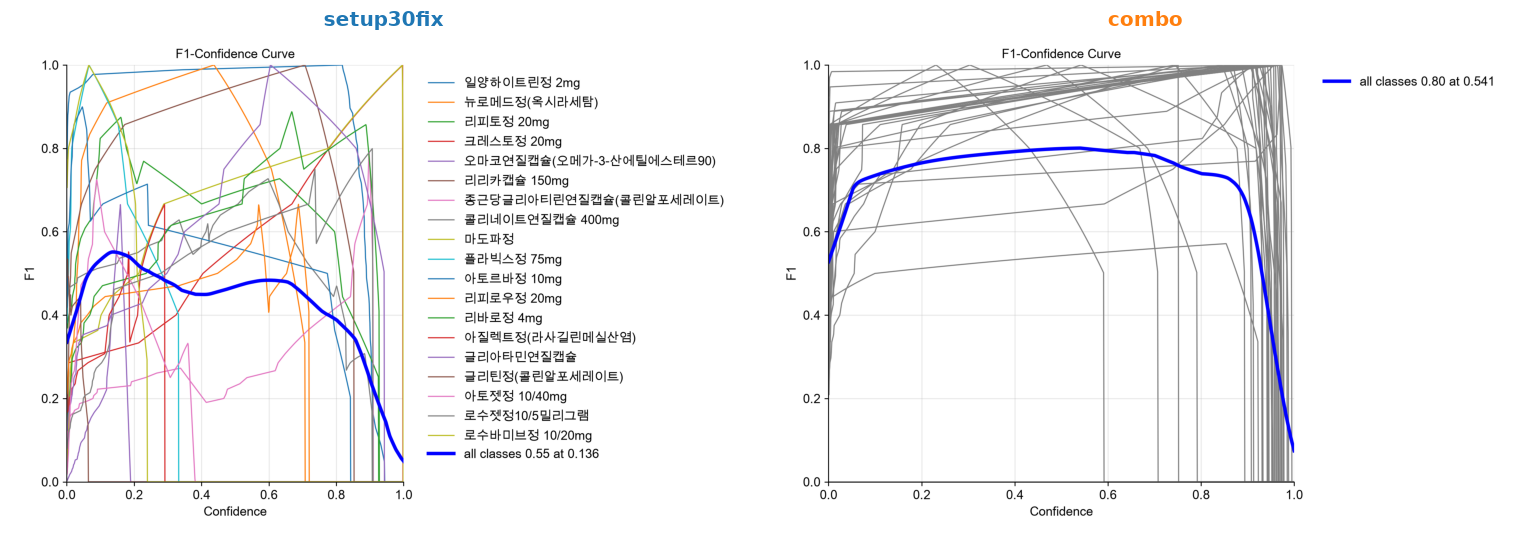

In [111]:
from PIL import Image

from models.evaluate import results_dir

# evaluate_fold(plots=True)가 저장한 ultralytics 그림을 그림 종류마다 분할끼리 나란히 놓는다
PLOT_SIZES = {
    "confusion_matrix_normalized.png": (9, 8),
    "BoxPR_curve.png": (7, 5),
    "BoxF1_curve.png": (7, 5),
}
val_root = results_dir(exp, RUNS_DIR) / "val"
for name, (w, h) in PLOT_SIZES.items():
    paths = {split: val_root / weights_of[split].parent.parent.name / name for split in done_splits}
    paths = {split: path for split, path in paths.items() if path.is_file()}
    if not paths:
        print(f"{name}이 없습니다. 5번 학습과 평가 칸을 먼저 실행하세요.")
        continue
    fig, axes = plt.subplots(1, len(paths), figsize=(w * len(paths), h), squeeze=False)
    for ax, (split, path) in zip(axes[0], paths.items(), strict=True):
        ax.imshow(Image.open(path))
        ax.set_title(split_label(split), color=SPLIT_COLORS[split], fontsize=13)
        ax.axis("off")
    fig.tight_layout()
    plt.show()

## 7. 학습 곡선

epoch마다 모델이 어떻게 나아졌는지 보는 그림입니다. 윗줄은 loss(틀린 정도, 낮을수록 좋음), 아랫줄은 검증 점수(높을수록 좋음)입니다. 색은 분할, 실선은 train, 점선(×)은 val입니다. 같은 그림이 run 폴더의 `results.png`로도 저장됩니다.

- **box_loss**: 박스 위치·크기가 틀린 정도, **cls_loss**: 약 이름이 틀린 정도, **dfl_loss**: 박스 경계를 정밀하게 잡는 정도
- **mAP50 / mAP50-95 / mAP75-95**: 6-1과 같은 점수를 epoch마다 잰 것입니다. 별표는 mAP75-95가 가장 높았던 epoch(= `best.pt`)입니다.

**좋은 모습**: loss는 train·val 모두 **매끄럽게 내려가다 평평해지고** 두 선의 간격이 좁은 것. mAP는 꾸준히 오르다 마지막에 평평해지는 것. 확인할 점은 세 가지입니다. val loss가 갑자기 치솟으면 학습률이 너무 큰 신호, train loss만 내려가고 val loss가 다시 오르면 **과적합**(학습 사진만 외움), 마지막 epoch에도 mAP가 계속 오르고 있으면 **epoch가 부족**한 것입니다.

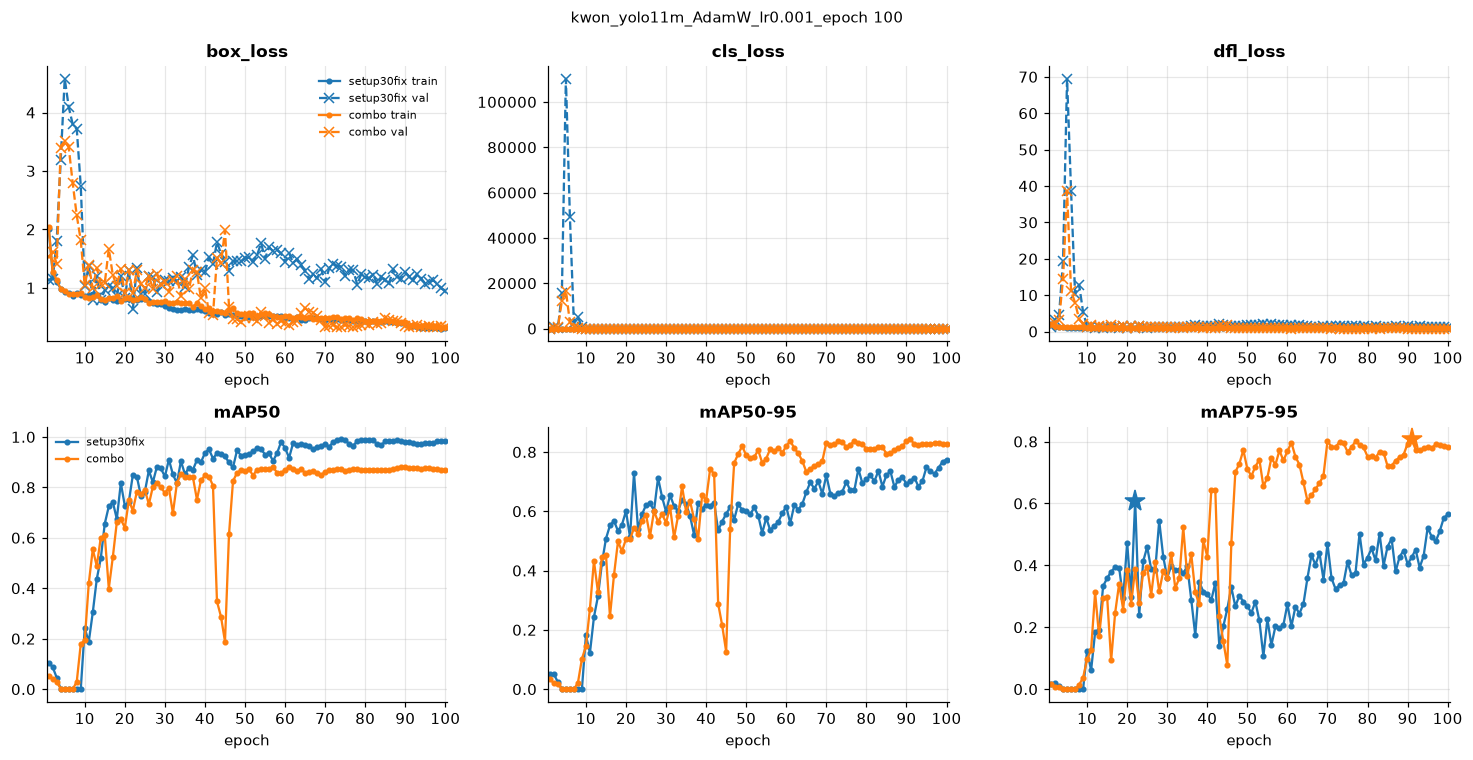

In [112]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from models.train import MAIN_METRIC_KEY

METRIC_KEYS = ["metrics/mAP50(B)", "metrics/mAP50-95(B)", MAIN_METRIC_KEY]

# ultralytics가 매 epoch 쓰는 results.csv를 분할·fold별로 읽는다 (run 폴더 이름 끝이 _fold<k>)
histories = {}
for path in sorted(exp_dir.glob("*/results.csv")):
    history = pd.read_csv(path)
    history.columns = history.columns.str.strip()
    run, fold = path.parent.name.rsplit("_", 1)
    histories[(split_of(run), fold)] = history
# 범례가 SPLITS 순서(세팅 → 조합)로 나오게 정렬한다
histories = dict(
    sorted(
        histories.items(),
        key=lambda kv: (SPLITS.index(kv[0][0]) if kv[0][0] in SPLITS else 99, kv[0][1]),
    )
)

if not histories:
    print(f"{exp_dir}에 results.csv가 없습니다. 학습 셀을 먼저 실행하세요.")
else:
    first = next(iter(histories.values()))
    loss_names = [c.removeprefix("train/") for c in first.columns if c.startswith("train/")]
    n_cols = max(len(loss_names), len(METRIC_KEYS))
    fig, axes = plt.subplots(2, n_cols, figsize=(4.5 * n_cols, 7), squeeze=False)
    # 색 = 분할 (6번 그림과 같음). 범례는 분할마다 첫 fold에만 붙인다
    labeled = set()
    for (split, _fold), history in histories.items():
        color, epoch = SPLIT_COLORS.get(split, "gray"), history["epoch"]
        name_tag = None if split in labeled else split_label(split)
        labeled.add(split)
        # 윗줄: loss. 실선은 train, 점선은 val. val이 오르는데 train만 내려가면 과적합이다
        for ax, name in zip(axes[0], loss_names, strict=False):
            ax.plot(
                epoch,
                history[f"train/{name}"],
                color=color,
                marker=".",
                label=name_tag and f"{name_tag} train",
            )
            ax.plot(
                epoch,
                history[f"val/{name}"],
                color=color,
                linestyle="--",
                marker="x",
                label=name_tag and f"{name_tag} val",
            )
            ax.set_title(name)
        # 아랫줄: 검증 mAP. 별은 best.pt를 고른 epoch (mAP75-95 최고)
        for ax, key in zip(axes[1], METRIC_KEYS, strict=False):
            ax.plot(epoch, history[key], color=color, marker=".", label=name_tag)
            ax.set_title(key.removeprefix("metrics/").removesuffix("(B)"))
        best = history[MAIN_METRIC_KEY].idxmax()
        axes[1, len(METRIC_KEYS) - 1].plot(
            epoch[best], history.loc[best, MAIN_METRIC_KEY], "*", color=color, markersize=14
        )
    n_epochs = max(int(h["epoch"].max()) for h in histories.values())
    for ax in axes.ravel():
        ax.set_xlabel("epoch")
        ax.set_xlim(0.5, n_epochs + 0.5)
        # epoch가 적으면 눈금을 직접 정해 소수 눈금(0.5, 0.6 …)이 나오지 않게 한다
        if n_epochs <= 10:
            ax.set_xticks(range(1, n_epochs + 1))
        else:
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    for ax in [*axes[0, len(loss_names) :], *axes[1, len(METRIC_KEYS) :]]:
        ax.set_visible(False)
    axes[0, 0].legend(fontsize=7)
    axes[1, 0].legend(fontsize=7)
    fig.suptitle(exp, fontsize=10)
    fig.tight_layout()
    plt.show()

## 실험 기록



Written for: 노트북 실험 기록 칸을 읽을 팀원

---

**6-1. 지표 한눈에 보기**
주 지표 mAP75-95는 세팅 0.499, 조합 0.372로 세팅이 0.127 높다. mAP50(0.848 / 0.743)과 mAP50-95(0.673 / 0.555)도 세팅이 높다. 반대로 conf 0.5로 고정한 정밀도(0.667 / 0.750)와 재현율(0.527 / 0.608)은 조합이 더 높다. 이렇게 갈리는 이유는 계산 방식에 있다. AP는 클래스별 점수의 평균이라, 조합 val에 들어 있는 AP 0인 약 몇 종이 평균을 크게 끌어내린다. 정밀도·재현율은 박스를 클래스 구분 없이 모두 모아 세므로 그 영향이 작다. 평균 IoU는 두 분할 모두 약 0.87로 같아서, 박스를 맞추는 정도는 분할과 관계없다. ≤5 재현율은 세팅이 n/a(세팅 분할은 희귀 약을 train에 고정)이고 조합은 0이다. fold가 하나뿐이라 표준편차 막대는 0이다.

**6-2. 클래스별 AP75-95**
- 왼쪽: 점이 없는 위쪽 약들은 fold 0 val에 없는 약이다. 조합 val에만 있는 빨강(≤5) 4종 16551, 31885, 33208, 27993은 AP가 0이다. 오른쪽 산점도에서 학습 bbox 수가 0인 점들이고, train에서 한 번도 보지 못한 약이다. 두 분할의 차이가 가장 큰 약은 16688이다(세팅 0.80, 조합 0). 16232, 32310, 18147, 20014도 세팅이 0.15–0.35 높다. 31863과 22074만 조합이 더 높다. 가장 잘 맞힌 약도 대부분 0.55–0.69에 머문다.
- 오른쪽 위: 그룹별 평균은 21+가 0.552 / 0.463, 6–20이 0.481 / 0.408로, 두 그룹 모두 세팅이 약 0.08 높다.
- 오른쪽 아래: 학습 bbox가 5–100개인 구간에서는 bbox 수와 점수 사이에 뚜렷한 경향이 없다. 10–20개 근처에서도 AP가 0.15–0.7로 넓게 퍼져 있고, 100개가 넘는 약도 0.53 정도다. 학습 데이터가 0개면 점수가 0이 되지만, 몇 개라도 있으면 그 뒤로는 양보다 약 자체의 난이도(닮은 약이 있는지 등)가 점수를 더 좌우하는 것으로 보인다.

**6-3. 예측 그림**
- 세팅: 3351(주황 원형)은 conf 0.90 이상으로 안정적으로 찾는다. 16232는 박스 위치는 맞지만 매번 22074로 잘못 답한다(0.68, 0.76). 길쭉한 흰 정제 3832는 conf가 0.62–0.63으로 낮거나, 아예 놓친 사진이 두 장이다.
- 조합: train에 없는 16551(흰 타원 DGTH)을 생김새가 닮은 35206으로 답한다(0.59–0.71). 학습에 없는 약에는 닮은 약 이름을 대는 모습이다. 역시 train에 없는 33208(빨강 원형)은 세 장 모두에서 박스조차 나오지 않았다. 29345는 한 장에서 35206으로 잘못 답했고, 두 장에서는 놓쳤다.
- 공통: 빨강 점선(예측)이 초록 실선(정답)보다 약간 크게 잡힌 경우가 많다. 6-5에서 IoU가 0.95를 넘지 못하는 것과 맞는 모습이다.

**6-4. 신뢰도 기준별 보조 지표**
conf 기준을 높이면 정밀도는 오르고(세팅 0.51→0.94, 조합 0.60→0.98) 재현율은 내려간다(0.65→0.37, 0.80→0.33). 두 곡선은 conf 약 0.3에서 교차하므로, 지금 모델에는 고정 기준 0.5가 높은 편이다. 평균 IoU는 어느 기준에서도 0.87로 평평하다. conf는 어떤 박스를 남길지만 바꾸고, 남은 박스가 얼마나 잘 맞는지는 바꾸지 않는다는 뜻이다. 조합의 ≤5 재현율은 모든 기준에서 0이다. 기준을 낮춰도 찾지 못하므로 문턱값 문제가 아니라 학습에 없는 약이라서 생기는 문제다. conf 0.1에서도 세팅 재현율이 0.65에 그친다. 매칭은 같은 클래스끼리만 하므로, 박스는 찾았지만 클래스를 틀린 경우도 놓친 것으로 세어진다.

**6-5. 박스 맞춤과 놓친 알약**
- 왼쪽: 짝지은 박스의 IoU는 모두 0.78–0.95에 있고 0.85–0.875에 가장 많이 몰려 있다. 0.95를 넘는 쌍은 하나도 없다. 박스 위치는 꾸준히 맞히지만, mAP75-95 중 IoU 0.90·0.95 기준에서 대부분 탈락하므로 주 지표의 상한이 여기서 막힌다.
- 오른쪽: 세팅은 사진의 56%에서 알약을 1개 놓쳤고, 개수가 정확히 맞은 사진은 37%다. 박스를 더 그린 경우는 2%뿐이다. 조합은 오차가 양쪽으로 넓다. 2개 이상 놓친 사진이 21%(−4는 예측이 하나도 없는 사진), 박스를 하나 더 그린 사진이 20%다. 이 그림은 클래스를 보지 않고 개수만 세므로, 0이라고 해서 모두 정답이라는 뜻은 아니다.

**6-6. 혼동 행렬(정규화)**
클래스가 50개가 넘어 이 크기로는 축 이름을 읽기 어렵고, 특정 약 쌍을 짚기는 힘들다. 전체 모양만 보면 진한 칸은 몇 개뿐이고 옅은 칸이 여기저기 흩어져 있다. 오답이 한 쌍에 몰리지 않고 여러 약에 퍼져 있다는 뜻이다. 조합이 세팅보다 흩어진 칸이 더 많다. 클래스별 혼동은 6-2 표와 닮은 약 쌍 혼동 수(0–1건)로 보는 편이 낫다.

**6-6. PR 곡선**
세팅의 all classes mAP50은 0.848이다. 약 20종 중 절반 이상이 0.995이고, 낮은 약은 아질렉트정 0.256, 콜리네이트연질캡슐 0.421, 리피로우정 0.572다. 소수의 약이 평균을 깎고 있다. 조합은 0.743이다. 클래스가 많아 범례가 생략됐지만, 정밀도 0.3–0.45에서 평평하게 이어지는 회색 선이 여러 개 있다. 처음부터 오답이 섞여 나오는 약들이다. 평균 곡선은 세팅이 정밀도 약 0.9에서, 조합이 약 0.8에서 시작한다.

**6-6. F1 곡선**
두 분할 모두 F1 최고값은 0.59이고, 그 지점의 conf는 세팅 0.088, 조합 0.157로 매우 낮다. conf 0.5에서는 F1이 0.45–0.5로 내려간다. 모델이 맞는 예측에도 낮은 신뢰도를 주고 있다는 뜻이고, 6-4에서 0.5 기준의 재현율이 낮은 것과 같은 현상이다. 클래스별 선은 val 표본이 적어 계단처럼 크게 출렁인다.

**7. 학습 곡선**
- loss: 세팅에서 warmup(3 epoch)이 끝난 직후 epoch 4–7에 val loss가 폭발했다(box 약 4.1, cls 약 39,000, dfl 약 30). train loss는 그동안에도 정상적으로 내려갔으므로, 검증 때 모델 출력만 불안정했던 것이다. lr0 0.001이 AdamW에 크다는 신호일 수 있다. epoch 10 이후 val box loss는 세팅 약 1.0, 조합 약 1.2에서 평평해진다. 조합은 끝으로 갈수록 val이 조금 오르고 train과 간격이 벌어진다. 과적합이 시작되는 초기 신호로 볼 수 있다.
- mAP: 두 분할 모두 epoch 8 전까지는 거의 0이다. mAP50과 mAP50-95는 25 epoch 끝에서도 계속 오르고 있어 아직 덜 학습된 상태다. mAP75-95는 epoch마다 크게 출렁인다. 별표는 best epoch(세팅 18에서 0.499, 조합 21에서 0.377)다. 조합은 best 뒤로 0.30 근처까지 떨어진다.

---

**10 epoch로 바꿨는데 위 그림은 모두 25 epoch 결과입니다.** 학습 곡선의 x축이 25까지 가고, 점수도 기존 기록과 같습니다. 실험 이름에 epoch 수가 들어가지 않아서, `EPOCHS = 10`으로 바꿔도 같은 이름(`kwon_yolo11m_AdamW_lr0.001_run1`)이 되고 resume이 끝난 fold로 보고 학습을 건너뛰었습니다. 10 epoch로 실제로 다시 돌리려면 `TAG`를 `"e10"`처럼 바꿔 실험 이름을 다르게 해야 합니다.